# 8. Representations, class imbalance and group-based evaluation (train + validation only)

This notebook answers three open research questions from the team's project setup guide
(Part 8) that notebooks 03–07 did not settle:

* **Q2. How do TF-IDF and Bag-of-Words compare?** Notebook 04 compared BoW + LR (C=1) with
  *tuned* TF-IDF models, which mixes the representation with the tuning. Here the model is
  held fixed and only the representation changes. Word vs BPE subword (Q1) is re-checked
  under the stronger model.
* **Q4. How does class imbalance affect rare fallacy detection?**
* **Q6. Does performance decrease when similar arguments are prevented from appearing on both
  sides of the split?** Near-duplicate clusters are built, then cross-validation that keeps
  each cluster in one fold (group-based) is compared with ordinary stratified cross-validation.

The test split is **not loaded** here (team rule 4: keep the predefined test set untouched).

In [1]:
import sys, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_validate
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from src.config import RESULTS, FIGURES, PROCESSED, SEED
from src.data import load_dataset, get_splits
from src.features import word_tfidf
from src.text import tokenize
from src.models import logreg, linear_svm
from src.evaluate import scores, per_class_f1

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_va, Y_va, _ = S["val"]; del S["test"]
print(len(X_tr), "train /", len(X_va), "val")

14341 train / 1768 val


## 8.1 Q2 (and Q1 revisited): representation comparison with the model held fixed

Six representations × two fixed models. Every vectoriser and the BPE tokenizer are fitted on
train only.

| representation | value of feature j for an argument |
|---|---|
| BoW counts | number of times token j occurs (notebook 03) |
| BoW binary | 1 if token j occurs, else 0 |
| TF-IDF | (1 + ln tf) · idf_j, row-normalised to unit L2 length |

Models: **LR (L2, C = 1, no class weights)**, the notebook-03 setting, and
**Linear SVM (C = 1, balanced)**, the setting selected in notebook 04.

In [2]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase
bpe = Tokenizer(BPE(unk_token="[UNK]")); bpe.normalizer = Lowercase(); bpe.pre_tokenizer = Whitespace()
bpe.train_from_iterator(X_tr.tolist(), trainer=BpeTrainer(vocab_size=5000, min_frequency=2, special_tokens=["[UNK]"]))
bpe_tr = [" ".join(e.tokens) for e in bpe.encode_batch(X_tr.tolist())]
bpe_va = [" ".join(e.tokens) for e in bpe.encode_batch(X_va.tolist())]

word = dict(tokenizer=tokenize, token_pattern=None, lowercase=False, min_df=2, max_df=0.95)
sub = dict(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2, max_df=0.95)
reps = {
    ("word uni", "BoW counts"):  (CountVectorizer(**word), X_tr, X_va),
    ("word uni", "BoW binary"):  (CountVectorizer(binary=True, **word), X_tr, X_va),
    ("word uni", "TF-IDF"):      (TfidfVectorizer(sublinear_tf=True, **word), X_tr, X_va),
    ("word uni+bi", "BoW counts"): (CountVectorizer(ngram_range=(1, 2), **word), X_tr, X_va),
    ("word uni+bi", "BoW binary"): (CountVectorizer(ngram_range=(1, 2), binary=True, **word), X_tr, X_va),
    ("word uni+bi", "TF-IDF"):     (TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, **word), X_tr, X_va),
    ("BPE uni", "BoW counts"):   (CountVectorizer(**sub), bpe_tr, bpe_va),
    ("BPE uni", "TF-IDF"):       (TfidfVectorizer(sublinear_tf=True, **sub), bpe_tr, bpe_va),
}
models = {"LR L2 C=1 (nb03 setting)": lambda: logreg("l2", 1.0),
          "Linear SVM C=1 balanced (nb04 choice)": lambda: linear_svm(1.0, "balanced")}
rows = []
for (tok, rep), (v, a, b) in reps.items():
    A = v.fit_transform(a); B = v.transform(b)
    for mname, mk in models.items():
        P = mk().fit(A, Y_tr).predict(B)
        rows.append({"tokens": tok, "representation": rep, "model": mname, "features": A.shape[1],
                     **{k: scores(Y_va, P)[k] for k in ["macro_f1", "micro_f1"]}})
q2 = pd.DataFrame(rows)
q2.to_csv(RESULTS / "val_q2_representations.csv", index=False)
q2.pivot_table(index=["tokens", "representation"], columns="model", values="macro_f1").round(4)

model                       LR L2 C=1 (nb03 setting)  \
tokens      representation                             
BPE uni     BoW counts                        0.7712   
            TF-IDF                            0.5433   
word uni    BoW binary                        0.7538   
            BoW counts                        0.7593   
            TF-IDF                            0.5299   
word uni+bi BoW binary                        0.7705   
            BoW counts                        0.7931   
            TF-IDF                            0.5056   

model                       Linear SVM C=1 balanced (nb04 choice)  
tokens      representation                                         
BPE uni     BoW counts                                     0.7377  
            TF-IDF                                         0.7746  
word uni    BoW binary                                     0.7626  
            BoW counts                                     0.7328  
            TF-IDF                                         0.7810  
word uni+bi BoW binary                                     0.7926  
            BoW counts                                     0.7891  
            TF-IDF                                         0.8229

**Reading Q2.** Compare rows within a column (same model). The ordering of BoW and TF-IDF
can depend on the model: unregularised-ish LR at C = 1 on L2-normalised TF-IDF rows is
effectively *more* penalised than on raw counts (the features are smaller), which is why
TF-IDF can look worse under the notebook-03 setting. With the SVM the comparison is fair.

## 8.2 Q4: class imbalance and rare fallacies

Same representation (word uni+bi TF-IDF) and same SVM, with and without class weighting.
`balanced` multiplies the hinge loss of positives of label k by n / (2 n_k), so a label with
1% prevalence gets about 50× weight on its positives.

In [3]:
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr); B = vec.transform(X_va)
f_none = per_class_f1(Y_va, linear_svm(1.0, None).fit(A, Y_tr).predict(B))
f_bal = per_class_f1(Y_va, linear_svm(1.0, "balanced").fit(A, Y_tr).predict(B))
q4 = pd.DataFrame({"train support": Y_tr.sum(0), "val support": Y_va.sum(0),
                   "F1 no weights": f_none, "F1 balanced": f_bal}, index=LABELS)
q4["gain"] = q4["F1 balanced"] - q4["F1 no weights"]
q4.to_csv(RESULTS / "val_q4_imbalance.csv")
rho, pval = spearmanr(q4["train support"], q4["F1 no weights"])
print(f"Spearman(train support, F1 without weights) = {rho:.2f} (p = {pval:.3f}, 16 labels)")
rho2, _ = spearmanr(q4["train support"], q4["gain"])
print(f"Spearman(train support, gain from balancing) = {rho2:.2f}")
q4.sort_values("train support", ascending=False).round(3)

Spearman(train support, F1 without weights) = 0.47 (p = 0.064, 16 labels)
Spearman(train support, gain from balancing) = -0.35


,train support,val support,F1 no weights,F1 balanced,gain
Slippery Slope,3925,490,0.895,0.891,-0.005
Appeal to Authority,2462,279,0.841,0.855,0.014
Bandwagon / Popularity,2268,262,0.771,0.815,0.044
Hasty Generalization,2008,213,0.788,0.793,0.006
False Cause / Causality,1675,211,0.834,0.835,0.001
Appeal to Emotion,1581,207,0.782,0.800,0.018
Composition,1118,151,0.870,0.847,-0.023
False Dilemma,1080,139,0.795,0.794,-0.001
Ad Hominem,957,129,0.712,0.762,0.050
Equivocation,733,81,0.814,0.821,0.007


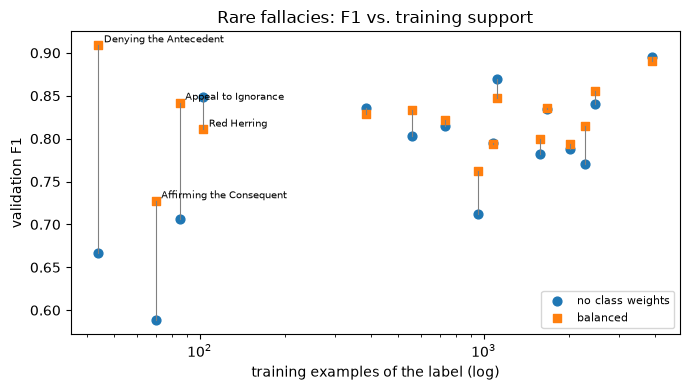

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(q4["train support"], q4["F1 no weights"], label="no class weights", s=40)
ax.scatter(q4["train support"], q4["F1 balanced"], label="balanced", s=40, marker="s")
for lab, r in q4.iterrows():
    ax.plot([r["train support"]] * 2, [r["F1 no weights"], r["F1 balanced"]], c="grey", lw=0.8)
    if r["train support"] < 150: ax.annotate(lab, (r["train support"], r["F1 balanced"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("training examples of the label (log)"); ax.set_ylabel("validation F1")
ax.set_title("Rare fallacies: F1 vs. training support"); ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIGURES / "q4_imbalance.png", dpi=150); plt.show()

Caveat: the four rarest labels have 5–19 validation positives, so a single argument moves
their F1 by 0.05–0.2. The Spearman correlation is across only 16 labels; it describes this
dataset, it does not establish that support *causes* the F1 differences (rare labels are also
the conceptually harder ones such as Red Herring).

## 8.3 Q6: near-duplicate clustering

Arguments in train + val are linked when their TF-IDF cosine similarity is ≥ τ (same
representation as notebook 02: English stop words removed, uni+bigrams). Connected
components of that graph are the **groups**. Labels are never used, and the test split is
excluded. Single-linkage chaining can create one giant group at low τ, so several τ are
checked.

In [5]:
tv = pd.concat([S["train"][2], S["val"][2]], ignore_index=True)
X_tv = tv["argument"]; Y_tv = tv[LABELS].values.astype(int)
V = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform(X_tv)

def near_dup_groups(V, tau, batch=2000):
    r, c = [], []
    for s in range(0, V.shape[0], batch):
        M = (V[s:s + batch] @ V.T).tocoo(); keep = M.data >= tau
        r.append(M.row[keep] + s); c.append(M.col[keep])
    r, c = np.concatenate(r), np.concatenate(c)
    G = sp.coo_matrix((np.ones(len(r)), (r, c)), shape=(V.shape[0],) * 2)
    return connected_components(G, directed=False)[1]

groups, crow = {}, []
for tau in [0.9, 0.8, 0.7, 0.6]:
    g = near_dup_groups(V, tau); sz = np.bincount(g); groups[tau] = g
    crow.append({"tau": tau, "groups": len(sz), "largest group": int(sz.max()),
                 "largest group %": 100 * sz.max() / len(g),
                 "args in multi-member groups": int((sz[g] > 1).sum())})
clusters = pd.DataFrame(crow); clusters.round(2)

,tau,groups,largest group,largest group %,args in multi-member groups
0,0.9,15441,46,0.29,1095
1,0.8,14598,257,1.60,2214
2,0.7,13738,535,3.32,3143
3,0.6,12714,973,6.04,4196


In [6]:
out = tv[["id", "split"]].copy()
for tau, g in groups.items(): out[f"group_tau{int(tau * 100)}"] = g
PROCESSED.mkdir(parents=True, exist_ok=True)
out.to_csv(PROCESSED / "near_dup_groups_trainval.csv", index=False)
print("saved", PROCESSED / "near_dup_groups_trainval.csv")
big = np.bincount(groups[0.8]).argmax()
print("Largest τ=0.8 group, 3 members:"); [print(" -", t[:140]) for t in X_tv[groups[0.8] == big].head(3)]

saved E:\ML_project\LFD_updated\data\processed\near_dup_groups_trainval.csv
Largest τ=0.8 group, 3 members:
 - If we allow students to use calculators in math class, they might become dependent on technology and eventually lose all basic arithmetic sk
 - If we allow students to use calculators in math class, they'll become dependent on technology and forget basic arithmetic entirely.
 - If we allow students to use calculators in math class, they will become dependent on technology and forget basic arithmetic skills within a 


[None, None, None]

## 8.4 Q6: group-based vs ordinary 5-fold cross-validation

* **Ordinary:** `MultilabelStratifiedKFold`, which can put two members of a cluster on
  opposite sides of a fold boundary.
* **Group-based:** `GroupKFold(shuffle=True)` on the τ groups. No cluster ever spans training
  and evaluation folds.

The pipeline (TF-IDF → Linear SVM, C = 1, balanced) is refitted inside every fold, so the
vocabulary is learned only from that fold's training part. A τ is skipped when its largest
group exceeds 20% of the data, because then the folds stop being comparable in size.

In [7]:
pipe = lambda: make_pipeline(word_tfidf(ngram_range=(1, 2)), linear_svm(1.0, "balanced"))
def cv_run(splits, name, tau=None):
    t = time.time()
    r = cross_validate(pipe(), X_tv, Y_tv, cv=splits, scoring=["f1_macro", "f1_micro"])
    return {"scheme": name, "tau": tau, "macro_f1 mean": r["test_f1_macro"].mean(),
            "macro_f1 sd": r["test_f1_macro"].std(), "micro_f1 mean": r["test_f1_micro"].mean(),
            "micro_f1 sd": r["test_f1_micro"].std(), "seconds": round(time.time() - t)}
q6 = [cv_run(list(MultilabelStratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv)),
             "ordinary (multilabel-stratified)")]
for _, c in clusters.iterrows():
    if c["largest group %"] > 20: print("skip tau", c.tau, "(giant group)"); continue
    g = groups[c.tau]
    q6.append(cv_run(list(GroupKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv, g)),
                     "group-based", c.tau))
q6 = pd.DataFrame(q6); q6.to_csv(RESULTS / "val_q6_group_cv.csv", index=False); q6.round(4)

,scheme,tau,macro_f1 mean,macro_f1 sd,micro_f1 mean,micro_f1 sd,seconds
0,ordinary (multilabel-stratified),NaN,0.8134,0.0098,0.8295,0.0068,10
1,group-based,0.9,0.7516,0.0200,0.8244,0.0030,10
2,group-based,0.8,0.7338,0.0132,0.8197,0.0056,10
3,group-based,0.7,0.7092,0.0153,0.8176,0.0114,10
4,group-based,0.6,0.7083,0.0225,0.8150,0.0196,10


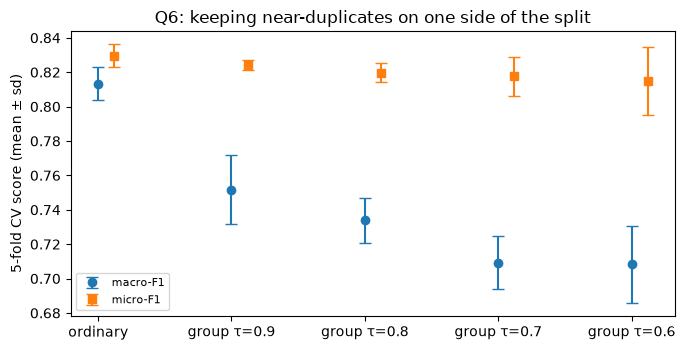

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.6))
lbl = ["ordinary"] + [f"group τ={t:g}" for t in q6.tau[1:]]
ax.errorbar(range(len(q6)), q6["macro_f1 mean"], yerr=q6["macro_f1 sd"], fmt="o", capsize=4, label="macro-F1")
ax.errorbar(np.arange(len(q6)) + 0.12, q6["micro_f1 mean"], yerr=q6["micro_f1 sd"], fmt="s", capsize=4, label="micro-F1")
ax.set_xticks(range(len(q6))); ax.set_xticklabels(lbl); ax.set_ylabel("5-fold CV score (mean ± sd)")
ax.set_title("Q6: keeping near-duplicates on one side of the split"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "q6_group_cv.png", dpi=150); plt.show()

**Reading Q6.** The gap between the ordinary row and each group row is the part of the
ordinary CV score that came from evaluating on near-copies of training arguments. Lower τ
groups more loosely related arguments together, so it removes more template overlap. The
fold-to-fold standard deviation is the noise floor for comparing rows. This complements the
overlap buckets of notebooks 06 and 10, which measure the same effect on fixed val/test
splits instead of by re-splitting.

### Sanity check: is the macro-F1 drop an artefact?
`GroupKFold` does not stratify labels. If a rare label had **zero** positives in an
evaluation fold, its F1 would be scored 0 and macro-F1 would fall for a bookkeeping reason.
We check the minimum number of positives per label per fold.

In [9]:
def fold_positives(splits):
    return np.array([Y_tv[te].sum(0) for _, te in splits])
chk = {"ordinary": fold_positives(MultilabelStratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv))}
for tau in [0.9, 0.8, 0.7, 0.6]:
    chk[f"group τ={tau}"] = fold_positives(GroupKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv, groups[tau]))
pd.DataFrame({k: v.min(0) for k, v in chk.items()}, index=LABELS).tail(6)

,ordinary,group τ=0.9,group τ=0.8,group τ=0.7,group τ=0.6
Circular Reasoning,126,120,110,116,101
Straw Man,84,78,74,79,73
Red Herring,24,21,21,14,17
Appeal to Ignorance,19,15,11,10,17
Affirming the Consequent,16,10,9,9,8
Denying the Antecedent,9,5,5,2,6


No fold is empty for any label, so the drop is not a scoring artefact.

### Why macro-F1 falls much more than micro-F1
The share of each label's examples that sit inside a multi-member near-duplicate group:

In [10]:
g8 = groups[0.8]; in_multi = np.bincount(g8)[g8] > 1
conc = pd.Series({lab: Y_tv[in_multi, k].sum() / Y_tv[:, k].sum() for k, lab in enumerate(LABELS)},
                 name="share in near-duplicate groups (τ=0.8)")
from sklearn.model_selection import cross_val_predict
pred_ord = cross_val_predict(pipe(), X_tv, Y_tv, cv=list(MultilabelStratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv)))
pred_grp = cross_val_predict(pipe(), X_tv, Y_tv, cv=list(GroupKFold(5, shuffle=True, random_state=SEED).split(X_tv, Y_tv, g8)))
q6_lab = pd.DataFrame({"train+val support": Y_tv.sum(0), "share in groups": conc.values,
                       "F1 ordinary CV": per_class_f1(Y_tv, pred_ord), "F1 group CV τ=0.8": per_class_f1(Y_tv, pred_grp)}, index=LABELS)
q6_lab["drop"] = q6_lab["F1 ordinary CV"] - q6_lab["F1 group CV τ=0.8"]
q6_lab.to_csv(RESULTS / "val_q6_per_label.csv")
r, p = spearmanr(q6_lab["share in groups"], q6_lab["drop"])
print(f"Spearman(share in groups, F1 drop) = {r:.2f} (p = {p:.3f})")
q6_lab.sort_values("share in groups", ascending=False).round(3)

Spearman(share in groups, F1 drop) = 0.57 (p = 0.020)


,train+val support,share in groups,F1 ordinary CV,F1 group CV τ=0.8,drop
Denying the Antecedent,49,0.776,0.901,0.381,0.520
Affirming the Consequent,82,0.744,0.764,0.296,0.468
Red Herring,122,0.582,0.764,0.689,0.075
Appeal to Ignorance,95,0.411,0.820,0.749,0.072
Composition,1269,0.250,0.817,0.823,-0.006
Circular Reasoning,632,0.203,0.821,0.742,0.079
Slippery Slope,4415,0.140,0.900,0.900,-0.001
False Cause / Causality,1886,0.123,0.839,0.824,0.015
False Dilemma,1219,0.098,0.799,0.795,0.004
Hasty Generalization,2221,0.089,0.768,0.760,0.008


The rare labels (Denying the Antecedent, Affirming the Consequent, Red Herring, Appeal to
Ignorance) are mostly written from a few templates, so when a template cannot appear on both
sides of the split, the model loses most of what it "knew" about them. Frequent labels are
spread over many templates and barely change. Micro-F1 is dominated by frequent labels and
hides this; macro-F1 exposes it. **Answer to Q6: yes, performance decreases (macro-F1 0.81 →
0.71–0.75 depending on τ), and the decrease is concentrated in the rare, templated fallacies.**